# 06. Model Training — Focal Loss Experiment

This notebook creates a separate Focal Loss experiment for the NEU-DET detector. It preserves `models/best_model.keras` and writes the new checkpoint to `models/focal_experiment/best_model_focal.keras`.

Expected project structure:
- `data/NEU-DET/`
- `src/data/dataset.py`
- `models/anchors.npy`
- `models/best_model.keras` (existing baseline checkpoint)

Run cells from top to bottom.

## 1. Imports and project paths

In [1]:
import os, sys, json, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), Path.cwd().parent]
     if (p / "src" / "data" / "dataset.py").exists()),
    None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from the project root or notebooks folder.")

sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

DATASET_PATH = PROJECT_ROOT / "data" / "NEU-DET"
MODELS_DIR = PROJECT_ROOT / "models"
FOCAL_DIR = MODELS_DIR / "focal_experiment"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "training"
FOCAL_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_ROOT)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

Project: d:\Industrial Surface Defect Detection and Classification Using CNN,Transfer Learning and Tensorflow
TensorFlow: 2.10.0
GPU: []


## 2. Configuration

In [2]:
IMAGE_SIZE = 224
GRID_SIZE = 7
NUM_CLASSES = 6
NUM_ANCHORS = 5
BATCH_SIZE = 8
EPOCHS = 30
LEARNING_RATE = 1e-4
PATIENCE = 5
OUTPUT_CHANNELS = 5 + NUM_CLASSES

CLASS_NAMES = [
    "crazing", "inclusion", "patches",
    "pitted_surface", "rolled-in_scale", "scratches"
]
INPUT_SHAPE = (IMAGE_SIZE, IMAGE_SIZE, 3)

print("Input:", INPUT_SHAPE)
print("Output:", (GRID_SIZE, GRID_SIZE, NUM_ANCHORS, OUTPUT_CHANNELS))

Input: (224, 224, 3)
Output: (7, 7, 5, 11)


## 3. Load data splits

In [3]:
from src.data.dataset import get_dataset_splits

train, val, test = get_dataset_splits(str(DATASET_PATH))

print("Train:", len(train), "Validation:", len(val), "Test:", len(test))
print("Sample keys:", train[0].keys())
print("First image:", train[0]["image"])
print("First sample boxes:", np.asarray(train[0]["boxes"]).shape)
print("First sample labels:", np.asarray(train[0]["labels"]).shape)

assert len(train) and len(val) and len(test)

Train: 1151 Validation: 288 Test: 360
Sample keys: dict_keys(['image', 'boxes', 'labels', 'stratify'])
First image: d:\Industrial Surface Defect Detection and Classification Using CNN,Transfer Learning and Tensorflow\data\NEU-DET\train\images\rolled-in_scale\rolled-in_scale_32.jpg
First sample boxes: (1, 4)
First sample labels: (1,)


## 4. Load the saved anchors

In [4]:
ANCHORS_PATH = MODELS_DIR / "anchors.npy"
if not ANCHORS_PATH.exists():
    raise FileNotFoundError(f"Missing {ANCHORS_PATH}. Generate anchors in your previous workflow.")

anchors = np.load(ANCHORS_PATH).astype(np.float32)
assert anchors.shape == (NUM_ANCHORS, 2), anchors.shape
assert np.all(anchors > 0)
print(anchors)

[[0.1828321  0.24619976]
 [0.28540698 0.51598006]
 [0.21671906 0.910609  ]
 [0.6913246  0.32715988]
 [0.81677145 0.9229429 ]]


## 5. Anchor IoU and target encoding

In [5]:
def calculate_anchor_iou(width, height, anchors_array):
    inter_w = np.minimum(width, anchors_array[:, 0])
    inter_h = np.minimum(height, anchors_array[:, 1])
    intersection = inter_w * inter_h
    union = width * height + anchors_array[:, 0] * anchors_array[:, 1] - intersection
    return intersection / np.maximum(union, 1e-9)


def encode_targets(boxes, labels, anchors_array):
    target = np.zeros(
        (GRID_SIZE, GRID_SIZE, NUM_ANCHORS, OUTPUT_CHANNELS),
        dtype=np.float32
    )
    assigned = set()

    for box, label in zip(boxes, labels):
        xmin, ymin, xmax, ymax = map(float, box)
        label = int(label)

        if not (0 <= xmin < xmax <= 1 and 0 <= ymin < ymax <= 1):
            raise ValueError(f"Invalid normalized box: {box}")
        if not 0 <= label < NUM_CLASSES:
            raise ValueError(f"Invalid class ID: {label}")

        cx, cy = (xmin + xmax) / 2, (ymin + ymax) / 2
        width, height = xmax - xmin, ymax - ymin
        cell_x = min(int(cx * GRID_SIZE), GRID_SIZE - 1)
        cell_y = min(int(cy * GRID_SIZE), GRID_SIZE - 1)

        ious = calculate_anchor_iou(width, height, anchors_array)
        chosen = None
        for anchor_id in np.argsort(ious)[::-1]:
            key = (cell_y, cell_x, int(anchor_id))
            if key not in assigned:
                assigned.add(key)
                chosen = int(anchor_id)
                break

        if chosen is None:
            raise ValueError(f"No free anchor in grid cell ({cell_y}, {cell_x}).")

        aw, ah = anchors_array[chosen]
        tx = cx * GRID_SIZE - cell_x
        ty = cy * GRID_SIZE - cell_y
        tw = np.log(width / aw)
        th = np.log(height / ah)

        target[cell_y, cell_x, chosen, 0:4] = [tx, ty, tw, th]
        target[cell_y, cell_x, chosen, 4] = 1.0
        target[cell_y, cell_x, chosen, 5 + label] = 1.0

    return target


check_target = encode_targets(train[0]["boxes"], train[0]["labels"], anchors)
print("Target shape:", check_target.shape)
print("Positive anchors:", int(check_target[..., 4].sum()))
print("GT boxes:", len(train[0]["boxes"]))
assert check_target.shape == (7, 7, 5, 11)
assert int(check_target[..., 4].sum()) == len(train[0]["boxes"])

Target shape: (7, 7, 5, 11)
Positive anchors: 1
GT boxes: 1


## 6. Image preprocessing and data pipelines

In [6]:
def load_image(path):
    raw = tf.io.read_file(path)
    image = tf.io.decode_image(raw, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, [IMAGE_SIZE, IMAGE_SIZE])
    image = tf.cast(image, tf.float32)
    return tf.keras.applications.mobilenet_v2.preprocess_input(image)


def generator(samples):
    for sample in samples:
        image = load_image(str(sample["image"]))
        target = encode_targets(sample["boxes"], sample["labels"], anchors)
        yield image, target


signature = (
    tf.TensorSpec((IMAGE_SIZE, IMAGE_SIZE, 3), tf.float32),
    tf.TensorSpec((GRID_SIZE, GRID_SIZE, NUM_ANCHORS, OUTPUT_CHANNELS), tf.float32)
)

def make_dataset(samples, training=False):
    ds = tf.data.Dataset.from_generator(
        lambda: generator(samples),
        output_signature=signature
    )
    if training:
        ds = ds.shuffle(min(len(samples), 1000), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train, training=True)
val_ds = make_dataset(val, training=False)

for image_batch, target_batch in train_ds.take(1):
    print("Image batch:", image_batch.shape)
    print("Target batch:", target_batch.shape)

Image batch: (8, 224, 224, 3)
Target batch: (8, 7, 7, 5, 11)


## 7. Load the original baseline model

This model is used only as initialization. The baseline checkpoint is not overwritten. If it is missing, the notebook builds a new MobileNetV2 detector.

In [7]:
BASELINE_PATH = MODELS_DIR / "best_model.keras"

def build_detector():
    inputs = tf.keras.Input(shape=INPUT_SHAPE, name="image")
    backbone = tf.keras.applications.MobileNetV2(
        input_shape=INPUT_SHAPE, include_top=False, weights="imagenet"
    )
    backbone.trainable = False
    x = backbone(inputs, training=False)
    x = tf.keras.layers.Conv2D(
        NUM_ANCHORS * OUTPUT_CHANNELS, 1, padding="same", name="detector_head"
    )(x)
    outputs = tf.keras.layers.Reshape(
        (GRID_SIZE, GRID_SIZE, NUM_ANCHORS, OUTPUT_CHANNELS)
    )(x)
    return tf.keras.Model(inputs, outputs, name="mobilenetv2_defect_detector")


if BASELINE_PATH.exists():
    model = tf.keras.models.load_model(BASELINE_PATH, compile=False)
    print("Loaded baseline initialization:", BASELINE_PATH)
else:
    model = build_detector()
    print("Built fresh MobileNetV2 detector with ImageNet weights.")

expected_shape = (GRID_SIZE, GRID_SIZE, NUM_ANCHORS, OUTPUT_CHANNELS)
assert tuple(model.output_shape[1:]) == expected_shape, model.output_shape
print("Output shape:", model.output_shape)



Loaded baseline initialization: d:\Industrial Surface Defect Detection and Classification Using CNN,Transfer Learning and Tensorflow\models\best_model.keras
Output shape: (None, 7, 7, 5, 11)


## 8. Focal Loss

This function applies sigmoid focal loss to objectness. Positive and negative objectness terms are averaged separately to prevent the many negative anchors from dominating only because they are more numerous.

In [8]:
def detector_loss_focal(y_true, y_pred, alpha=0.25, gamma=2.0):
    positive_mask = y_true[..., 4:5]

    # Smooth L1 box regression on positive anchors.
    box_true = y_true[..., 0:4]
    box_pred = y_pred[..., 0:4]
    diff = tf.abs(box_true - box_pred)
    smooth_l1 = tf.where(diff < 1.0, 0.5 * tf.square(diff), diff - 0.5)

    positive_count = tf.reduce_sum(positive_mask)
    box_loss = tf.reduce_sum(smooth_l1 * positive_mask) / tf.maximum(
        positive_count * 4.0, 1.0
    )

    # Sigmoid focal loss for objectness.
    obj_true = y_true[..., 4:5]
    obj_logits = y_pred[..., 4:5]
    probability = tf.sigmoid(obj_logits)
    bce = tf.nn.sigmoid_cross_entropy_with_logits(
        labels=obj_true, logits=obj_logits
    )

    p_t = obj_true * probability + (1.0 - obj_true) * (1.0 - probability)
    alpha_t = obj_true * alpha + (1.0 - obj_true) * (1.0 - alpha)
    focal = alpha_t * tf.pow(1.0 - p_t, gamma) * bce

    negative_mask = 1.0 - positive_mask
    positive_obj = tf.reduce_sum(focal * positive_mask) / tf.maximum(
        tf.reduce_sum(positive_mask), 1.0
    )
    negative_obj = tf.reduce_sum(focal * negative_mask) / tf.maximum(
        tf.reduce_sum(negative_mask), 1.0
    )
    objectness_loss = positive_obj + negative_obj

    # Softmax classification on positive anchors.
    class_ce = tf.nn.softmax_cross_entropy_with_logits(
        labels=y_true[..., 5:], logits=y_pred[..., 5:]
    )
    class_loss = tf.reduce_sum(
        class_ce * tf.squeeze(positive_mask, axis=-1)
    ) / tf.maximum(positive_count, 1.0)

    total = 5.0 * box_loss + objectness_loss + class_loss
    return total, box_loss, objectness_loss, class_loss


print("Focal loss defined.")

Focal loss defined.


## 9. Optimizer and training steps

Both steps below explicitly call `detector_loss_focal` (not the original `detector_loss`).

In [9]:
optimizer = tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE)

@tf.function
def train_step(images, targets):
    with tf.GradientTape() as tape:
        predictions = model(images, training=True)
        total, box, obj, cls = detector_loss_focal(targets, predictions)

    gradients = tape.gradient(total, model.trainable_variables)
    pairs = [(g, v) for g, v in zip(gradients, model.trainable_variables) if g is not None]
    optimizer.apply_gradients(pairs)
    return total, box, obj, cls


@tf.function
def validation_step(images, targets):
    predictions = model(images, training=False)
    return detector_loss_focal(targets, predictions)


print("Training step uses Focal Loss.")
print("Validation step uses Focal Loss.")

Training step uses Focal Loss.
Validation step uses Focal Loss.


## 10. Train and save the Focal Loss checkpoint

The checkpoint is saved separately. The original `models/best_model.keras` is never written by this loop.

In [10]:
best_model_path = FOCAL_DIR / "best_model_focal.keras"

history = {
    "train_loss": [], "val_loss": [],
    "box_loss": [], "objectness_loss": [], "class_loss": []
}
best_val_loss = float("inf")
wait = 0

for epoch in range(EPOCHS):
    train_losses, val_losses, components = [], [], []
    print(f"\\nEpoch {epoch + 1}/{EPOCHS}")

    for images, targets in train_ds:
        total, box, obj, cls = train_step(images, targets)
        train_losses.append(float(total.numpy()))
        components.append([float(box.numpy()), float(obj.numpy()), float(cls.numpy())])

    for images, targets in val_ds:
        total, _, _, _ = validation_step(images, targets)
        val_losses.append(float(total.numpy()))

    train_loss = float(np.mean(train_losses))
    val_loss = float(np.mean(val_losses))
    comp = np.mean(components, axis=0)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["box_loss"].append(float(comp[0]))
    history["objectness_loss"].append(float(comp[1]))
    history["class_loss"].append(float(comp[2]))

    print(f"Training loss: {train_loss:.4f}")
    print(f"Validation loss: {val_loss:.4f}")
    print(f"Box: {comp[0]:.4f} | Objectness: {comp[1]:.4f} | Class: {comp[2]:.4f}")

    if np.isfinite(val_loss) and val_loss < best_val_loss:
        best_val_loss = val_loss
        wait = 0
        model.save(best_model_path)
        print("Best Focal checkpoint saved:", best_model_path)
    else:
        wait += 1
        print(f"No improvement: {wait}/{PATIENCE}")
        if wait >= PATIENCE:
            print("Early stopping.")
            break

if not best_model_path.exists():
    raise RuntimeError("Focal checkpoint was not saved. Check validation losses.")

print("Training complete. Best validation loss:", best_val_loss)
print("Checkpoint:", best_model_path)

\nEpoch 1/30
Training loss: 0.2970
Validation loss: 0.8112
Box: 0.0373 | Objectness: 0.0785 | Class: 0.0320
Best Focal checkpoint saved: d:\Industrial Surface Defect Detection and Classification Using CNN,Transfer Learning and Tensorflow\models\focal_experiment\best_model_focal.keras
\nEpoch 2/30
Training loss: 0.3077
Validation loss: 0.7777
Box: 0.0448 | Objectness: 0.0513 | Class: 0.0325
Best Focal checkpoint saved: d:\Industrial Surface Defect Detection and Classification Using CNN,Transfer Learning and Tensorflow\models\focal_experiment\best_model_focal.keras
\nEpoch 3/30
Training loss: 0.2352
Validation loss: 0.7209
Box: 0.0319 | Objectness: 0.0482 | Class: 0.0274
Best Focal checkpoint saved: d:\Industrial Surface Defect Detection and Classification Using CNN,Transfer Learning and Tensorflow\models\focal_experiment\best_model_focal.keras
\nEpoch 4/30
Training loss: 0.1856
Validation loss: 0.6624
Box: 0.0240 | Objectness: 0.0457 | Class: 0.0198
Best Focal checkpoint saved: d:\Indus

## 11. Plot and save training history

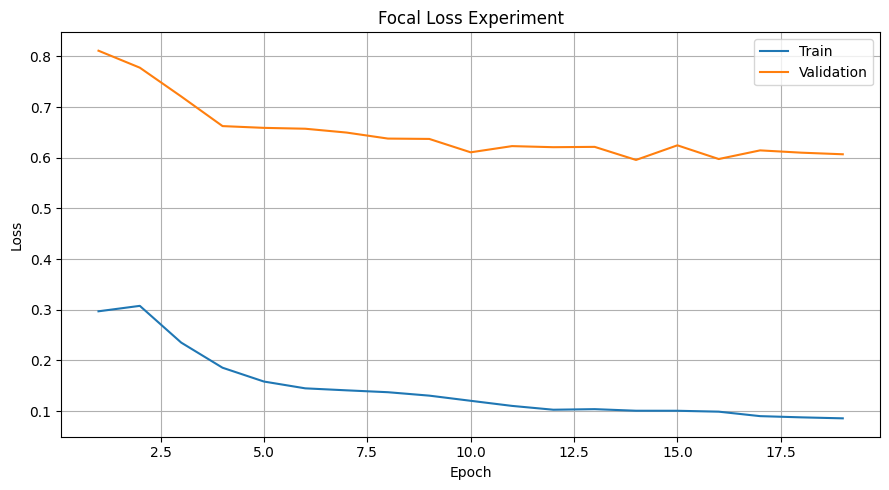

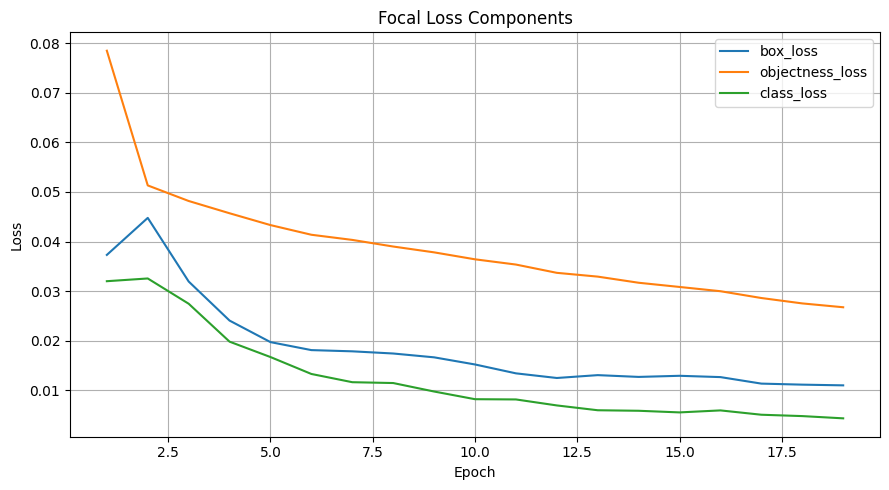

experiment                                           Focal Loss objectness
epochs_completed                                                        19
best_epoch                                                              14
best_validation_loss                                              0.595635
final_training_loss                                                0.08574
final_validation_loss                                             0.606837
checkpoint               d:\Industrial Surface Defect Detection and Cla...
classes                  [crazing, inclusion, patches, pitted_surface, ...
anchors                  [[0.18283210694789886, 0.24619975686073303], [...
dtype: object


In [11]:
epochs_ran = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(9, 5))
plt.plot(epochs_ran, history["train_loss"], label="Train")
plt.plot(epochs_ran, history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Focal Loss Experiment")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "focal_training_loss.png", dpi=150)
plt.show()

plt.figure(figsize=(9, 5))
for key in ["box_loss", "objectness_loss", "class_loss"]:
    plt.plot(epochs_ran, history[key], label=key)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Focal Loss Components")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "focal_loss_components.png", dpi=150)
plt.show()

history_df = pd.DataFrame(history)
history_df.to_csv(OUTPUT_DIR / "focal_training_history.csv", index_label="epoch")
best_epoch = int(np.argmin(history["val_loss"])) + 1
summary = {
    "experiment": "Focal Loss objectness",
    "epochs_completed": len(history["train_loss"]),
    "best_epoch": best_epoch,
    "best_validation_loss": float(min(history["val_loss"])),
    "final_training_loss": float(history["train_loss"][-1]),
    "final_validation_loss": float(history["val_loss"][-1]),
    "checkpoint": str(best_model_path),
    "classes": CLASS_NAMES,
    "anchors": anchors.tolist()
}
(OUTPUT_DIR / "focal_training_summary.json").write_text(
    json.dumps(summary, indent=2), encoding="utf-8"
)
print(pd.Series(summary))

## 12. Verify checkpoint and preserve baseline

In [12]:
focal_model = tf.keras.models.load_model(best_model_path, compile=False)
print("Focal checkpoint exists:", best_model_path.exists())
print("Focal checkpoint size:", best_model_path.stat().st_size, "bytes")
print("Focal output shape:", focal_model.output_shape)

print("Original baseline exists:", BASELINE_PATH.exists())
if BASELINE_PATH.exists():
    print("Original baseline size:", BASELINE_PATH.stat().st_size, "bytes")

print("Notebook 06 Focal Loss training completed.")

Focal checkpoint exists: True
Focal checkpoint size: 22573099 bytes
Focal output shape: (None, 7, 7, 5, 11)
Original baseline exists: True
Original baseline size: 22573099 bytes
Notebook 06 Focal Loss training completed.
